# How well is EI optimized? A deterministic, gradient-refined EI as the base policy

## Description

<!-- Written 2026-11-12 before the first run (pre-registration). Issue #13; research_log/decisions/0007; Tim's question on candidate selection. -->

**Question.**
- π₀ (EI) so far is the argmax of the PFN's EI over a fresh random candidate set at every (task, step, replicate). The set is 1024 shifted Sobol points plus 64 Gaussian perturbations of the incumbent at each of σ ∈ {0.01, 0.05, 0.2}, with no refinement.
- That makes π₀ stochastic. On noise-free tasks, this is the *only* noise in the round-1 labels: the continuations differ only in EI's candidate sets.
- It also confounds the advantage over EI with EI's own optimizer error. A candidate with higher EI than the sampled argmax "beats EI", although EI properly optimized would have chosen it.
- A scratch check (600 labeled states, not tracked) gave the motivation:
  - the sampled argmax reaches about 99.5% of the best EI found (median), so the value lost is small;
  - but picks from two replicate candidate sets differ by a median distance of 0.005–0.018. That is large where the incumbent is within one PFN bin of f\* (57% of the labeled states; 0007 §3).
- This experiment asks:
  1. how suboptimal and how stochastic the current EI is;
  2. whether a deterministic, gradient-refined EI loses anything in BO;
  3. whether it can be π₀ for relabeling. With deterministic π₀ on noise-free tasks, a label needs a single continuation and no cross-fitting.

**Setup** (`experimental/ei_opt.py`, `tasks/ei_opt.py`). Four variants of EI, the same PFN (pfn_large, fp32), the same EI closed form:
- `sampled`: the current π₀.
- `fixed`: candidate sets of the same sizes, but a function of the data only. The Sobol set is unshifted, and the perturbation directions around the incumbent are fixed: one draw shared by all lanes and steps.
- `sampled+refine`, `fixed+refine`:
  - the top 8 candidates by EI are the starts;
  - Adam on x through the PFN (it is differentiable in x) maximizes log EI: 100 steps, lr 0.01 cosine-annealed to 1e-4, clamped to [0, 1];
  - the best iterate per start is kept (iterates at an evaluated point are excluded);
  - the pick is the best of the refined starts and the base argmax, so refinement never lowers EI.
- *Part A (states).*
  - On the first 2000 labeled states of the pinned round-1 label set (split 4, d = 2), every variant picks under 4 replicate candidate sets.
  - Per pick: its EI relative to the best EI any variant found at the state, and the true f at the pick in PFN bins relative to the incumbent.
  - Per state and variant: the mean pairwise distance between replicate picks, and the sd of f at the picks.
- *Part B (rollouts).*
  - Full BO runs (n_init = 4, T = 20) of every variant on 1000 tasks of **split 0**: the tuning split, because this chooses π₀.
  - 4 replicates each: the replicate selects the candidate-set nuisance, which the fixed variants ignore.
  - Final regret per (task, variant, replicate): normalized regret (% of f_med − f\*), regret in PFN bins (ECDF units / 0.001), and log regret.
  - f\* is lowered by every run.

**What to look for.**
1. Part B, the decision: the paired difference (replicate mean per task) of `fixed+refine` − `sampled` in normalized regret, relative, with a bootstrap CI over tasks. Also its determinism: the share of tasks with replicate sd of the final regret < 1e-6 bins.
2. Part B, the size of the label noise π₀ induces: the replicate sd of the final normalized regret per task for each variant. `sampled` is the noise the round-1 labels carried.
3. Part B, the tail: the q90 and q95 of the per-task normalized regret, and the failure rate P(final regret > 10 bins), by variant.
4. Part A:
   - the EI ratio (median, q10, share < 0.99) and the replicate pick distance by variant;
   - by step t and by incumbent gap in bins: where does the sampled argmax lose most?

**GO / NO-GO** (rule `analysis/ei_opt.py::ei_opt_verdict`, worthwhile = 5% relative). This decides whether `fixed+refine` becomes π₀ for the next labels.
- **GO**: `fixed+refine` is deterministic (≥ 99% of tasks with replicate sd < 1e-6 bins) and not worse than `sampled` by 5% (the upper CI bound of the relative paired difference < +5%).
- **NO-GO**: not deterministic, or clearly worse (lower bound > +5%).
- **INCONCLUSIVE**: otherwise.

A *better* `fixed+refine` would be a bonus, not required. The point is removing the optimizer noise without losing performance.

**Limits.**
- Noise-free P0, d = 2, T = 20 only (pfn_large valid for n ≤ 100; contexts n ≤ 24).
- Refinement can still miss a better basin of EI that none of the top-8 starts lies in. Part A's EI ratio is relative to the best *found*, not the true maximum.
- GPU non-determinism could make "deterministic" variants differ across replicates; the determinism check measures exactly that.
- 1000 tasks is a pilot size for small effects.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.ei_opt import ei_opt_verdict, pick_dispersion
from anytime_acq.tasks.pfn_bo_inference import gap_stratum

SNAPSHOT = "results/ei_opt/sanity_20261112-090427"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached sanity experiment=ei_opt task.d=2 task.states.n_states=100 task.rollouts.n_tasks=50
```

|  |  |
|---|---|
| stage | sanity |
| sweep | `sanity_20261112-090427` |
| commit | `295a9b90b750` (tag `sweep/ei_opt/sanity_20261112-090427`) |
| backend / host | detached / ulysses |
| ran | 2026-11-12T09:04:29 → 2026-11-12T09:09:46 |
| members | 1: 1 done |
| compute | 5.3 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/ei_opt.yaml`):

```yaml
# @package _global_
# How well is EI optimized, and a deterministic gradient-refined EI as the base policy (issue #13, decision 0007).
# Pre-registration: notebooks/11_2026-11-12_ei_opt.ipynb.
defaults:
  - override /task: ei_opt

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  group: 256
  labels.path: api_round1/pilot_20261111-133311/0/tracking/artifacts/labels.pt
  labels.sha256: c27d893923d0f003ed7b1e1148ad6670c1f5fb061ac7cdf137eb2a8a64c678d9
  log_eps: 1.0e-06
  n_init_per_d: 2
  n_reps: 4
  name: ei_opt
  pfn: pfn_large
  refine.k: 8
  refine.lr: 0.01
  refine.steps: 100
  rollouts.n_tasks: 50
  rollouts.split: 0
  rollouts.task_draw.n_dense: 16384
  rollouts.task_draw.n_refine: 16
  rollouts.task_draw.refine_steps: 200
  rollouts.task_offset: 0
  states.n_states: 100
  states.task_draw.n_dense: 256
  states.task_draw.n_refine: 1
  states.task_draw.refine_steps: 1
  tf32: false
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
st, fin, spread, summary, paired = (snap.table(k) for k in ("states", "final", "spread", "summary", "paired"))
print("states:", st.state.nunique(), "| rollout tasks:", fin.task.nunique(), "| replicates:", fin.rep.nunique(),
      "| variants:", sorted(fin.variant.unique()))

member status: {'DONE': 1}
minutes: {'time/rollouts_s': 2.9, 'time/states_s': 2.4}
states: 100 | rollout tasks: 50 | replicates: 4 | variants: ['fixed', 'fixed+refine', 'sampled', 'sampled+refine']


## 1. Part A: how suboptimal and how stochastic is the EI pick at the labeled states?

EI ratio = EI of the pick / best EI any variant found at the state. Pick distance = mean pairwise distance between the 4 replicate picks. f sd = sd over replicates of the true f at the pick, in PFN bins.

In [ ]:
cols = ["variant", "ei_ratio_median", "ei_ratio_q10", "share_ei_ratio_below_0.99", "pick_dist_mean",
        "share_states_pick_dist_above_1e-3", "f_sd_bins_median", "f_sd_bins_mean"]
display(summary[cols].set_index("variant").round(4))
disp = pick_dispersion(st)
disp["stratum"] = gap_stratum(disp.gap_bins.to_numpy())
disp["t_bin"] = pd.cut(disp.t, [-1, 4, 9, 14, 20])
print("pick distance (mean) by incumbent gap stratum:")
display(disp.pivot_table(index="stratum", columns="variant", values="pick_dist", aggfunc="mean").round(4))
print("f sd over replicates (bins, mean) by gap stratum:")
display(disp.pivot_table(index="stratum", columns="variant", values="f_sd_bins", aggfunc="mean").round(3))
print("EI ratio (mean) by step:")
display(disp.pivot_table(index="t_bin", columns="variant", values="ei_ratio", aggfunc="mean", observed=True).round(4))

,ei_ratio_median,ei_ratio_q10,share_ei_ratio_below_0.99,pick_dist_mean,share_states_pick_dist_above_1e-3,f_sd_bins_median,f_sd_bins_mean
variant,,,,,,,
fixed,0.9950,0.9394,0.360,0.0000,0.00,0.0000,0.0000
fixed+refine,1.0000,1.0000,0.060,0.0000,0.00,0.0000,0.0000
sampled,0.9926,0.9389,0.425,0.0533,0.87,0.1345,4.0828
sampled+refine,1.0000,0.9961,0.085,0.0290,0.11,0.0009,1.1367


pick distance (mean) by incumbent gap stratum:


variant,fixed,fixed+refine,sampled,sampled+refine
stratum,,,,
1-10,0.0,0.0,0.0107,0.0001
10-100,0.0,0.0,0.0203,0.0001
<1,0.0,0.0,0.0738,0.0360
>100,0.0,0.0,0.0241,0.0744


f sd over replicates (bins, mean) by gap stratum:


variant,fixed,fixed+refine,sampled,sampled+refine
stratum,,,,
1-10,0.0,0.0,2.551,0.013
10-100,0.0,0.0,3.278,0.010
<1,0.0,0.0,3.416,1.161
>100,0.0,0.0,13.688,4.884


EI ratio (mean) by step:


variant,fixed,fixed+refine,sampled,sampled+refine
t_bin,,,,
"(-1, 4]",0.9849,1.0000,0.9795,0.9993
"(4, 9]",0.9699,0.9955,0.9721,0.9897
"(9, 14]",0.9906,0.9994,0.9853,0.9990
"(14, 20]",0.9804,0.9966,0.9838,0.9955


## 2. Part B: full BO runs on split 0 (paired over tasks, replicate means)

,norm_regret_mean,norm_regret_q90,norm_regret_q95,regret_bins_mean,fail_rate,rep_sd_norm_median,rep_sd_norm_mean,share_tasks_deterministic
variant,,,,,,,,
fixed,0.6092,1.0924,2.2089,1.1232,0.060,0.0000,0.0000,1.00
fixed+refine,0.7938,0.9778,4.8962,1.3744,0.060,0.0000,0.0000,1.00
sampled,0.7380,1.9325,2.6006,1.1580,0.035,0.0092,0.2324,0.24
sampled+refine,0.7904,0.9899,4.8899,1.3628,0.060,0.0003,0.0070,0.26


,a,b,metric,n,delta,lo,hi,rel,rel_lo,rel_hi,frac_a_better,frac_tied
0,sampled+refine,sampled,norm_regret,50,0.0524,-0.1852,0.3520,0.0710,-0.2510,0.4769,0.34,0.24
1,sampled+refine,sampled,regret_bins,50,0.2048,-0.7126,1.4003,0.1769,-0.6153,1.2092,0.34,0.24
2,sampled+refine,sampled,log_regret,50,0.1025,-0.0649,0.2617,-0.0228,0.0144,-0.0581,0.28,0.24
3,fixed,sampled,norm_regret,50,-0.1288,-0.2885,0.0204,-0.1745,-0.3910,0.0276,0.58,0.24
4,fixed,sampled,regret_bins,50,-0.0348,-0.4412,0.4955,-0.0300,-0.3810,0.4279,0.58,0.24
5,fixed,sampled,log_regret,50,-0.1307,-0.2593,0.0010,0.0290,0.0576,-0.0002,0.50,0.24
6,fixed+refine,sampled,norm_regret,50,0.0558,-0.1807,0.3565,0.0756,-0.2449,0.4830,0.36,0.24
7,fixed+refine,sampled,regret_bins,50,0.2163,-0.6972,1.4116,0.1868,-0.6020,1.2189,0.36,0.24
8,fixed+refine,sampled,log_regret,50,0.1096,-0.0581,0.2744,-0.0243,0.0129,-0.0609,0.30,0.24


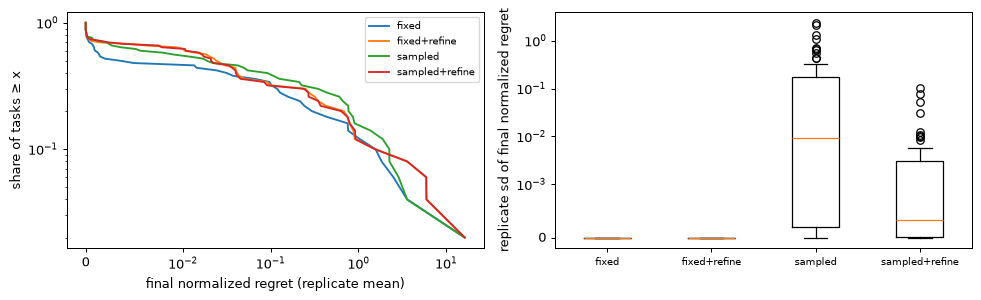

In [ ]:
cols = ["variant", "norm_regret_mean", "norm_regret_q90", "norm_regret_q95", "regret_bins_mean", "fail_rate",
        "rep_sd_norm_median", "rep_sd_norm_mean", "share_tasks_deterministic"]
display(summary[cols].set_index("variant").round(4))
show = ["a", "b", "metric", "n", "delta", "lo", "hi", "rel", "rel_lo", "rel_hi", "frac_a_better", "frac_tied"]
display(paired[show].round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
m = fin.groupby(["task", "variant"]).norm_regret.mean().unstack()
for v in m.columns:
    x = np.sort(m[v].to_numpy()); ax[0].plot(x, 1 - np.arange(len(x)) / len(x), label=v)
ax[0].set_xscale("symlog", linthresh=0.01); ax[0].set_yscale("log"); ax[0].set_xlabel("final normalized regret (replicate mean)")
ax[0].set_ylabel("share of tasks ≥ x"); ax[0].legend(fontsize=8)
sp = spread.pivot_table(index="task", columns="variant", values="sd_norm")
ax[1].boxplot([sp[v].to_numpy() for v in sp.columns], tick_labels=list(sp.columns)); ax[1].set_yscale("symlog", linthresh=1e-3)
ax[1].set_ylabel("replicate sd of final normalized regret"); ax[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

## Verdict

In [ ]:
print("verdict (analysis/ei_opt.py::ei_opt_verdict):", ei_opt_verdict(summary, paired))

verdict (analysis/ei_opt.py::ei_opt_verdict): INCONCLUSIVE
